# New Zealand Electricity Demand & Price Forecasting

## 1. Exploratory Data Analysis (EDA)

### Project Overview

This project investigates electricity consumption and its monetary value across five regions of New Zealand using data provided by the Electricity Authority.

The dataset covers November 2024 to October 2026, with observations recorded at 30-minute trading intervals.

### Research Objectives

1. Analyse electricity demand patterns across New Zealand.
2. Identify daily, weekly, and seasonal consumption trends.
3. Investigate the relationship between electricity demand and its monetary value.
4. Develop machine learning models to forecast electricity demand and market value.
5. Compare statistical and machine learning forecasting methods.

### Tools
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn and XGBoost

**Data Source:** New Zealand Electricity Authority (EMI)

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("NZ Electricity Forecasting")
print("Pandas version:", pd.__version__)

NZ Electricity Forecasting
Pandas version: 3.1.1


In [25]:
from pathlib import Path

# Locate the data folder
data_folder = Path.cwd().parent / "data"

# Find the CSV file
csv_files = list(data_folder.glob("*.csv"))

print("Available datasets:")
for file in csv_files:
    print(file.name)

Available datasets:
Demand_trends_20261118145637.csv
electricity_demand_clean.csv


In [26]:
# Inspect the first 20 lines of the CSV file

with open(csv_files[0], "r", encoding="utf-8-sig") as file:
    for i in range(20):
        line = file.readline()
        print(f"{i}: {line.strip()}")

0: Demand trends
1: 
2: From www.emi.ea.govt.nz provided by the Electricity Authority (New Zealand)
3: Run at: 20261118145637
4: 
5: Parameters
6: Date range,01 Nov 2024 - 31 Oct 2026
7: Region type,Zone
8: Time scale,Trading period
9: Show,GWh
10: 
11: Period start,Period end,Region ID,Region,Demand (GWh),Demand ($)
12: 01/11/2024 00:00:00,01/11/2024 00:30:00,UNI,Upper North Island,0.541,7733.40
13: 01/11/2024 00:00:00,01/11/2024 00:30:00,CNI,Central North Island,0.377,5205.29
14: 01/11/2024 00:00:00,01/11/2024 00:30:00,LNI,Lower North Island,0.246,3061.64
15: 01/11/2024 00:00:00,01/11/2024 00:30:00,USI,Upper South Island,0.275,3430.31
16: 01/11/2024 00:00:00,01/11/2024 00:30:00,LSI,Lower South Island,0.433,5116.59
17: 01/11/2024 00:30:00,01/11/2024 01:00:00,UNI,Upper North Island,0.518,8050.77
18: 01/11/2024 00:30:00,01/11/2024 01:00:00,CNI,Central North Island,0.370,5546.38
19: 01/11/2024 00:30:00,01/11/2024 01:00:00,LNI,Lower North Island,0.234,3198.18


### 2.2 Importing the Dataset

The initial inspection identified 11 metadata lines preceding the column headers.

We will use Pandas to import the CSV file, skipping these metadata lines.

The dataset contains six variables:

| Variable | Description |
|---|---|
| Period start | Beginning of the trading period |
| Period end | End of the trading period |
| Region ID | Electricity region identifier |
| Region | Geographic region |
| Demand (GWh) | Electricity consumption in gigawatt-hours |
| Demand ($) | Monetary value associated with electricity demand |

The objective is to create a structured DataFrame suitable for exploratory analysis and predictive modelling.

In [27]:
# Load the electricity dataset
df = pd.read_csv(csv_files[0], skiprows=11)

# Display the first five observations
df.head()

,Period start,Period end,Region ID,Region,Demand (GWh),Demand ($)
0,01/11/2024 00:00:00,01/11/2024 00:30:00,UNI,Upper North Island,0.541,7733.40
1,01/11/2024 00:00:00,01/11/2024 00:30:00,CNI,Central North Island,0.377,5205.29
2,01/11/2024 00:00:00,01/11/2024 00:30:00,LNI,Lower North Island,0.246,3061.64
3,01/11/2024 00:00:00,01/11/2024 00:30:00,USI,Upper South Island,0.275,3430.31
4,01/11/2024 00:00:00,01/11/2024 00:30:00,LSI,Lower South Island,0.433,5116.59


### 2.3 Dataset Dimensions

We examine the dimensions of the dataset to determine the number of observations and variables available for analysis.

Each row represents electricity demand for one New Zealand region during a 30-minute trading period.

This information helps us understand the size of the dataset before proceeding with data cleaning and exploratory analysis.

In [28]:
# Check dataset dimensions
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])


Number of observations: 175200
Number of variables: 6


### 2.4 Data Types

Before conducting time-series analysis, we need to examine the data types of each variable.

The dataset contains three main types of information:

- **Temporal:** Start and end of each trading period.
- **Categorical:** Electricity region identifiers and names.
- **Numerical:** Electricity demand (GWh) and monetary value ($).

Correct data types are essential for statistical analysis, feature engineering, and predictive modelling.

In particular, the date columns must eventually be converted to datetime format.

In [29]:
# Examine column data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175200 entries, 0 to 175199
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Period start  175200 non-null  str    
 1   Period end    175200 non-null  str    
 2   Region ID     175200 non-null  str    
 3   Region        175200 non-null  str    
 4   Demand (GWh)  174936 non-null  float64
 5   Demand ($)    174936 non-null  float64
dtypes: float64(2), str(4)
memory usage: 8.0 MB


### 2.5 Converting Date Variables

The initial inspection revealed that both `Period start` and `Period end` were imported as strings.

For time-series analysis, these variables must be converted into datetime objects.

We will use Pandas to convert the timestamps using the format `DD/MM/YYYY HH:MM:SS`.

This conversion will allow us to:

- Extract hours, days, months, and years.
- Analyse daily and seasonal electricity consumption patterns.
- Sort observations chronologically.
- Create lagged variables for forecasting.

In [30]:
# Convert timestamp columns to datetime
df["Period start"] = pd.to_datetime(
    df["Period start"],
    format="%d/%m/%Y %H:%M:%S"
)

df["Period end"] = pd.to_datetime(
    df["Period end"],
    format="%d/%m/%Y %H:%M:%S"
)

# Verify conversion
df.dtypes

# Check the date range of the dataset
print("First observation:", df["Period start"].min())
print("Last observation:", df["Period end"].max())

First observation: 2024-11-01 00:00:00
Last observation: 2026-11-01 00:00:00


### 2.6 Missing Value Analysis

The dataset contains 175,200 observations across five electricity regions.

Initial inspection identified 264 missing values in both `Demand (GWh)` and `Demand ($)`.

Missing data may affect statistical analysis and forecasting accuracy.

Before deciding how to handle these observations, we will investigate:

- The number and percentage of missing values.
- Whether missing observations occur in particular regions.
- Whether the missing values in both numerical columns occur in the same rows.

No observations will be removed or modified at this stage.

In [31]:
# Calculate missing values and percentages
missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Percentage (%)": (df.isna().mean() * 100).round(3)
})

display(missing_summary)

# Count missing demand observations by region
missing_by_region = (
    df.groupby("Region")["Demand (GWh)"]
    .apply(lambda x: x.isna().sum())
)

print("\nMissing observations by region:")
print(missing_by_region)

# Check whether both demand variables are missing together
both_missing = (
    df["Demand (GWh)"].isna() &
    df["Demand ($)"].isna()
).sum()

print("\nRows missing both demand variables:", both_missing)

,Missing Values,Percentage (%)
Period start,0,0.000
Period end,0,0.000
Region ID,0,0.000
Region,0,0.000
Demand (GWh),264,0.151
Demand ($),264,0.151



Missing observations by region:
Region
Central North Island    41
Lower North Island      47
Lower South Island      66
Upper North Island      53
Upper South Island      57
Name: Demand (GWh), dtype: int64

Rows missing both demand variables: 264


### 2.7 Distribution of Missing Values by Region

Although only 0.151% of observations have missing demand values, their distribution may affect forecasting accuracy.

We will investigate whether missing observations are concentrated in particular electricity regions.

This analysis will help determine whether the missing values are isolated or potentially systematic.

In [32]:
# Count missing demand observations by region
missing_by_region = (
    df.groupby("Region")["Demand (GWh)"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

print("Missing observations by region:")
print(missing_by_region)

# Check whether both demand variables are missing together
both_missing = (
    df["Demand (GWh)"].isna() &
    df["Demand ($)"].isna()
).sum()

print("\nRows missing both variables:", both_missing)

Missing observations by region:
Region
Lower South Island      66
Upper South Island      57
Upper North Island      53
Lower North Island      47
Central North Island    41
Name: Demand (GWh), dtype: int64

Rows missing both variables: 264


### 2.8 Handling Missing Values

The dataset contains 264 observations (0.151%) with missing electricity demand and monetary values.

Because the proportion of missing data is very small, we will remove these observations using listwise deletion.

This approach simplifies the initial analysis without requiring estimated or imputed values.

The original dataset remains unchanged on disk.

**Note:** Removing observations may create gaps in the time series. These will need to be considered when constructing lagged features and forecasting models.

In [33]:
# Remove rows with missing demand values
df = df.dropna(subset=["Demand (GWh)", "Demand ($)"]).copy()

# Reset the DataFrame index
df = df.reset_index(drop=True)

# Verify the cleaned dataset
print("Observations remaining:", len(df))
print("Missing values remaining:", df.isna().sum().sum())

Observations remaining: 174936
Missing values remaining: 0


### 3.1 Descriptive Statistics

We examine the distribution of electricity demand and monetary value using descriptive statistics.

These statistics include the mean, median, standard deviation, minimum, maximum, and quartiles.

Understanding these distributions will help us identify variability and unusual values before developing forecasting models.

In [34]:
# Calculate descriptive statistics
df[["Demand (GWh)", "Demand ($)"]].describe().round(2)

,Demand (GWh),Demand ($)
count,174936.00,174936.00
mean,0.48,51492.58
std,0.16,66818.03
min,0.17,0.00
25%,0.36,3879.19
50%,0.47,33288.20
75%,0.56,78810.21
max,1.20,4644794.99


### 3.1.1 Interpretation of Descriptive Statistics

The descriptive statistics provide an initial understanding of electricity demand and its associated monetary value across New Zealand's five electricity regions.

**Electricity Demand (GWh)**

- **Mean:** 0.48 GWh per region per trading period.
- **Median:** 0.47 GWh, indicating that the distribution is reasonably balanced around its centre.
- **Standard deviation:** 0.16 GWh, suggesting moderate variability in electricity consumption.
- **Minimum:** 0.17 GWh.
- **Maximum:** 1.20 GWh, approximately 2.5 times the average demand.

The relatively small difference between the mean and median suggests that electricity demand is not strongly skewed overall.

**Electricity Monetary Value ($)**

- **Mean:** $51,492.58 per observation.
- **Median:** $33,288.20.
- **Standard deviation:** $66,818.03.
- **Minimum:** $0.
- **Maximum:** $4,644,794.99.

The substantial difference between the mean and median suggests a positively skewed distribution.

The maximum monetary value is considerably higher than the average, potentially reflecting periods of extreme wholesale electricity prices.

**Key Findings**

1. Electricity demand is relatively stable compared with its associated monetary value.
2. Monetary values exhibit substantial variability and potential extreme observations.
3. Demand and monetary value may require different forecasting approaches.
4. Further analysis is needed to identify seasonal patterns and investigate unusually high monetary values.

These findings provide a foundation for subsequent exploratory analysis and predictive modelling.

### 3.2 Monthly Electricity Demand Patterns

Electricity demand may vary throughout the year due to seasonal changes, temperature, and economic activity.

In New Zealand, winter typically occurs between June and August, while summer occurs between December and February.

To investigate potential seasonal patterns, we calculate the average electricity demand for each calendar month across the two-year observation period.

We first aggregate regional demand into total national demand for each trading period.

We then calculate the average national demand for each month of the year.

This approach allows us to compare typical electricity demand across different seasons.

In [35]:
# Calculate total NZ demand for each trading period
national_demand = (
    df.groupby("Period start")["Demand (GWh)"]
    .sum()
    .reset_index()
)

# Extract calendar month
national_demand["Month"] = national_demand["Period start"].dt.month

# Calculate average national demand by month
monthly_average = (
    national_demand.groupby("Month")["Demand (GWh)"]
    .mean()
)

# Add month names
monthly_average.index = pd.to_datetime(
    monthly_average.index,
    format="%m"
).month_name()

# Display results
print("Average National Electricity Demand by Month (GWh per trading period):")
display(monthly_average.round(3))

Average National Electricity Demand by Month (GWh per trading period):


/var/folders/vm/wpy4jwz9593d3_cf75gx3y180000gn/T/ipykernel_883/297810391.py:18: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  monthly_average.index = pd.to_datetime(


Month
January      2.173
February     2.263
March        2.258
April        2.267
May          2.410
June         2.514
July         2.643
August       2.659
September    2.493
October      2.364
November     2.297
December     2.230
Name: Demand (GWh), dtype: float64

### 3.3 Visualising Monthly Electricity Demand

A bar chart is used to compare average national electricity demand across the 12 calendar months.

The objective is to identify potential seasonal patterns in electricity consumption.

In particular, we investigate whether demand increases during New Zealand's winter months (June–August) compared with summer (December–February).

Each bar represents the average national electricity demand per 30-minute trading period for that calendar month, rather than total monthly consumption.

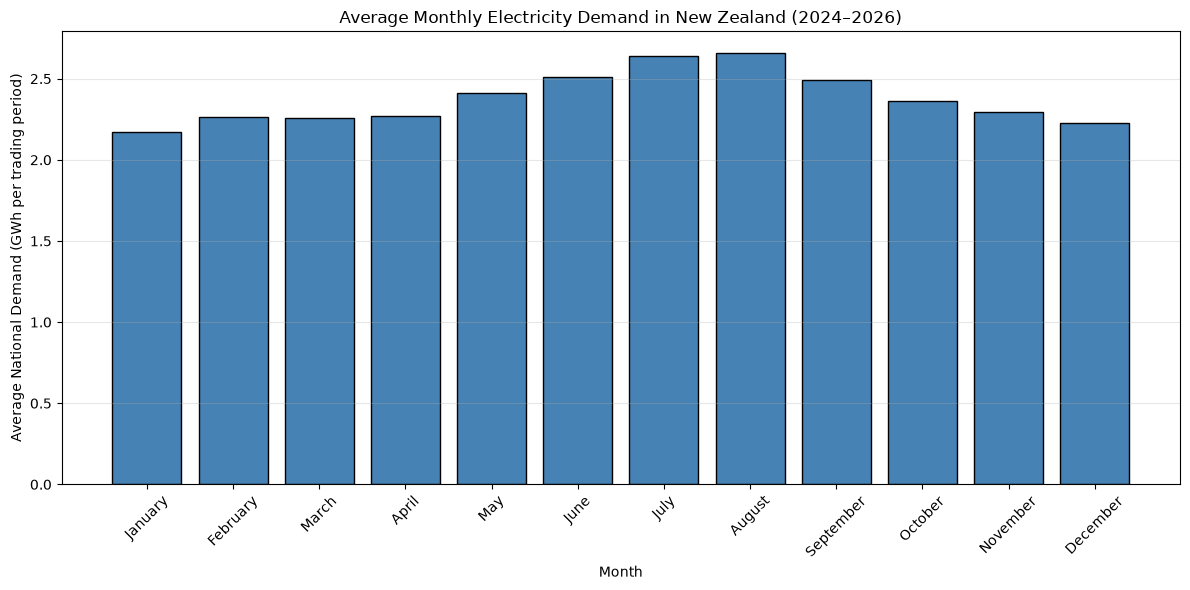

In [36]:
# Create a bar chart of average monthly electricity demand
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_average.index,
    monthly_average.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("Average Monthly Electricity Demand in New Zealand (2024–2026)")
plt.xlabel("Month")
plt.ylabel("Average National Demand (GWh per trading period)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.3.1 Interpretation of Monthly Electricity Demand

The monthly electricity demand analysis reveals a clear seasonal pattern across New Zealand.

**Key Findings**

- **Winter peak:** Average electricity demand is highest during July and August, reaching approximately 2.6 GWh per trading period.
- **Summer minimum:** Demand is lowest during December and January, averaging approximately 2.2 GWh.
- **Seasonal increase:** Electricity consumption rises progressively from autumn into winter.
- **Seasonal decline:** Demand decreases from late winter through spring and into summer.

**Possible Explanations**

The observed seasonal pattern is consistent with increased electricity consumption for residential and commercial heating during winter.

Temperature, daylight hours, and seasonal economic activity may also influence electricity demand.

However, these factors have not yet been tested statistically.

**Implications for Predictive Modelling**

The results suggest that seasonality should be incorporated into future forecasting models.

Potential predictive features include:

- Month of the year.
- Season (summer, autumn, winter, spring).
- Day of the week.
- Hour of the day.
- Historical electricity demand.

These variables may help machine learning models capture recurring electricity consumption patterns.

**Conclusion**

Electricity demand exhibits a noticeable annual seasonal cycle, with higher consumption during winter and lower consumption during summer.

This finding supports the inclusion of calendar-based features in subsequent forecasting models.

### 3.4 Electricity Demand by Hour of the Day

Electricity consumption varies throughout the day due to residential, commercial, and industrial activity.

This analysis investigates average national electricity demand across the 24 hours of the day.

**Objectives:**

- Identify peak electricity consumption hours.
- Identify periods of low electricity demand.
- Examine daily electricity consumption patterns.
- Determine whether the hour of the day could be a useful predictor in forecasting models.

National electricity demand is calculated by summing demand across all five electricity regions for each trading period.

Only trading periods containing observations from all five regions are included to prevent incomplete records from understating national demand.

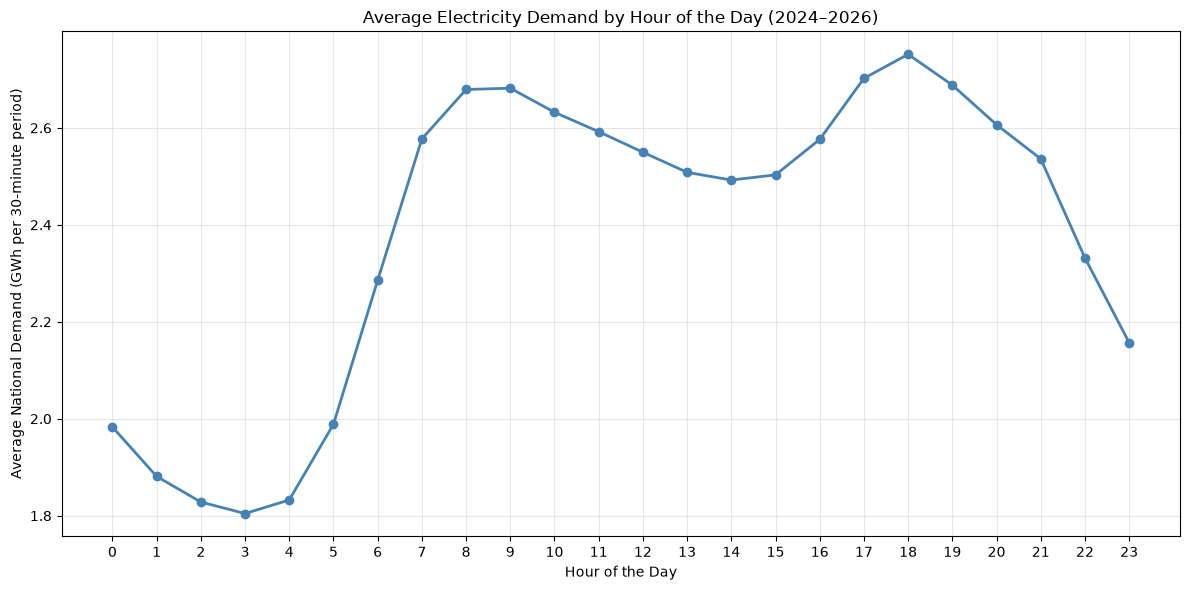

In [37]:
# Keep only trading periods with all five regions
complete_periods = (
    df.groupby("Period start")
    .filter(lambda x: x["Region ID"].nunique() == 5)
)

# Calculate national electricity demand per trading period
hourly_demand = (
    complete_periods.groupby("Period start")["Demand (GWh)"]
    .sum()
    .reset_index()
)

# Extract hour of the day
hourly_demand["Hour"] = hourly_demand["Period start"].dt.hour

# Calculate average national demand by hour
average_hourly_demand = (
    hourly_demand.groupby("Hour")["Demand (GWh)"]
    .mean()
)

# Create line graph
plt.figure(figsize=(12, 6))

plt.plot(
    average_hourly_demand.index,
    average_hourly_demand.values,
    marker="o",
    linewidth=2,
    color="steelblue"
)

plt.title("Average Electricity Demand by Hour of the Day (2024–2026)")
plt.xlabel("Hour of the Day")
plt.ylabel("Average National Demand (GWh per 30-minute period)")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.4.1 Interpretation of Hourly Electricity Demand

The analysis reveals a distinct daily electricity consumption pattern across New Zealand.

**Key Findings**

- **Overnight minimum:** Electricity demand is lowest at approximately 03:00, averaging 1.80 GWh per trading period.
- **Morning peak:** Demand increases sharply between 05:00 and 08:00, reaching approximately 2.68 GWh.
- **Afternoon decline:** Consumption gradually decreases during the afternoon, reaching approximately 2.49 GWh at 14:00.
- **Evening peak:** The highest average demand occurs at approximately 18:00, reaching 2.75 GWh.
- **Nighttime decline:** Demand decreases steadily after 19:00.

**Possible Explanations**

The morning peak may reflect increased residential activity as households prepare for work and school, alongside the beginning of commercial operations.

The evening peak may reflect increased residential electricity consumption associated with cooking, heating, and household activities.

Lower overnight demand is consistent with reduced commercial and residential activity.

These explanations are plausible but have not been independently tested.

**Implications for Predictive Modelling**

The results indicate that electricity demand follows a predictable daily cycle.

Hour of the day should therefore be considered an important feature in future forecasting models.

Additional features could include day of the week, season, and interactions between hour and season.

### 3.5 Regional Electricity Demand Analysis

Electricity consumption differs across New Zealand's five electricity regions.

This analysis compares average electricity demand per trading period across:

- Upper North Island
- Central North Island
- Lower North Island
- Upper South Island
- Lower South Island

The objective is to identify regional differences in electricity consumption and determine whether geographical location should be incorporated into forecasting models.

A bar chart is used to compare average electricity demand across regions.

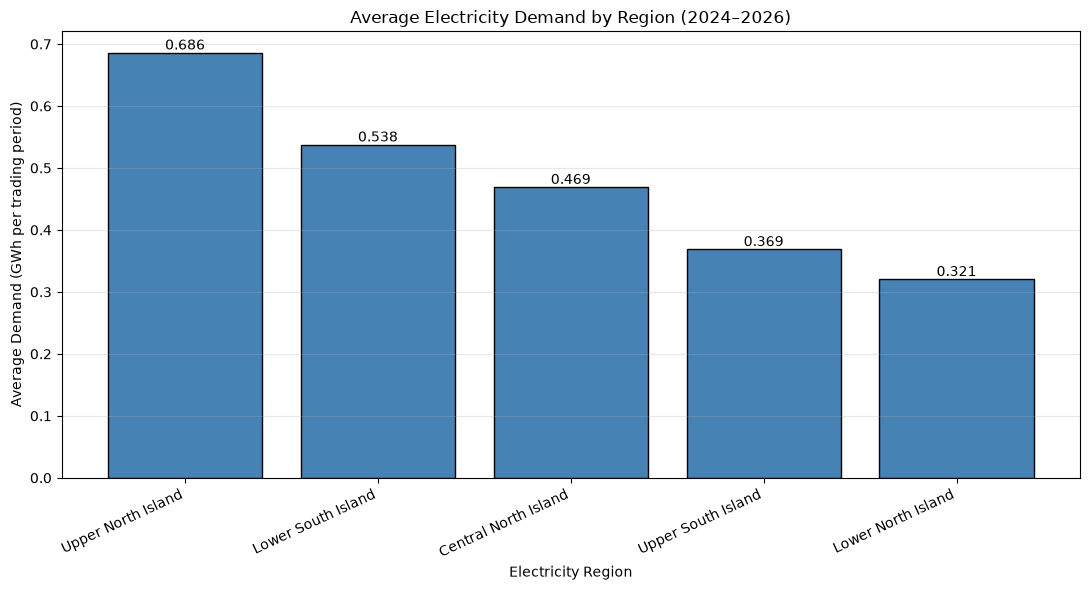

In [38]:
# Calculate average electricity demand by region
regional_demand = (
    df.groupby("Region")["Demand (GWh)"]
    .mean()
    .sort_values(ascending=False)
)

# Create bar chart
plt.figure(figsize=(11, 6))

bars = plt.bar(
    regional_demand.index,
    regional_demand.values,
    color="steelblue",
    edgecolor="black"
)

# Add values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{height:.3f}",
        ha="center"
    )

plt.title("Average Electricity Demand by Region (2024–2026)")
plt.xlabel("Electricity Region")
plt.ylabel("Average Demand (GWh per trading period)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.5.1 Interpretation of Regional Electricity Demand

The analysis reveals considerable differences in average electricity demand across New Zealand's five electricity regions.

**Key Findings**

- **Upper North Island:** Records the highest average electricity demand, at approximately 0.70 GWh per trading period.
- **Lower South Island:** Records the second-highest demand, averaging 0.538 GWh.
- **Central North Island:** Average demand is 0.469 GWh.
- **Upper South Island:** Average demand is 0.369 GWh.
- **Lower North Island:** Records the lowest average demand, at 0.321 GWh.

**Possible Explanations**

Higher demand in the Upper North Island may be associated with population concentration, commercial activity, and urban electricity consumption.

The relatively high demand in the Lower South Island may reflect electricity-intensive industrial activity.

These explanations are hypotheses and would require additional demographic and industrial data to verify.

**Implications for Predictive Modelling**

Regional differences indicate that geographical location should be considered when developing forecasting models.

Potential modelling approaches include:

1. Training separate forecasting models for each region.
2. Developing a single model incorporating region as a categorical predictor.
3. Comparing regional and national forecasting performance.

**Conclusion**

Electricity demand varies substantially across New Zealand's electricity regions.

Including regional information may improve forecasting accuracy by allowing models to capture geographical differences in consumption.

### 3.6 Electricity Demand Trends Over Time

Time-series analysis allows us to examine how electricity demand changes over an extended period.

This analysis investigates national electricity demand between November 2024 and October 2026.

**Objectives:**

- Identify long-term electricity demand trends.
- Examine recurring seasonal patterns.
- Compare demand across different periods.
- Identify unusual increases or decreases in consumption.

Daily electricity consumption is calculated by summing national demand across trading periods within each calendar day.

Only trading periods containing observations from all five electricity regions are included.

Days with incomplete trading-period coverage are excluded from this initial analysis to avoid understating daily consumption.

/var/folders/vm/wpy4jwz9593d3_cf75gx3y180000gn/T/ipykernel_883/3099109957.py:25: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  (expected_periods.index.dayofweek == 6) &
/var/folders/vm/wpy4jwz9593d3_cf75gx3y180000gn/T/ipykernel_883/3099109957.py:31: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  (expected_periods.index.dayofweek == 6) &


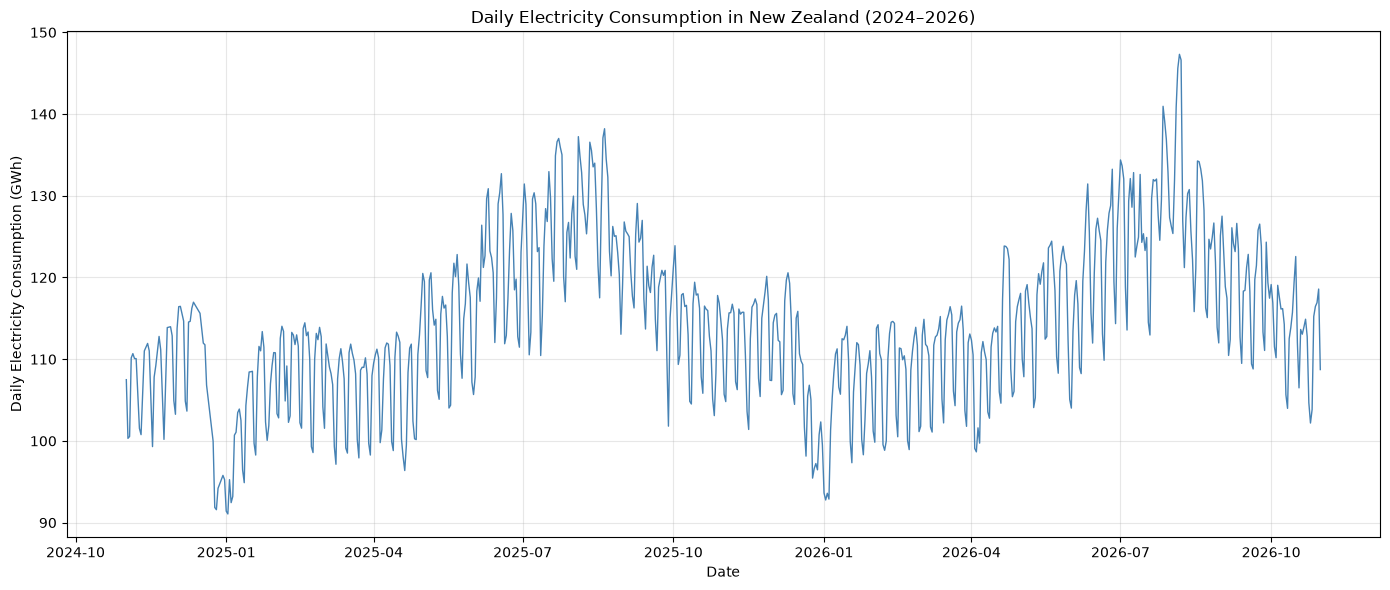

In [39]:
# Calculate national demand for complete trading periods
national_demand = (
    complete_periods.groupby("Period start")["Demand (GWh)"]
    .sum()
    .sort_index()
)

# Aggregate electricity consumption by day
daily_demand = national_demand.resample("D").sum()

# Count trading periods per day
daily_counts = national_demand.resample("D").count()

# Account for NZ daylight-saving transitions
# Normal day: 48 periods
# Daylight-saving start: 46 periods
# Daylight-saving end: 50 periods
expected_periods = pd.Series(
    48,
    index=daily_counts.index
)

expected_periods.loc[
    (expected_periods.index.month == 9) &
    (expected_periods.index.dayofweek == 6) &
    (expected_periods.index.day >= 24)
] = 46

expected_periods.loc[
    (expected_periods.index.month == 4) &
    (expected_periods.index.dayofweek == 6) &
    (expected_periods.index.day <= 7)
] = 50

# Keep days with complete coverage
daily_demand = daily_demand[
    daily_counts == expected_periods
]

# Visualise daily electricity consumption
plt.figure(figsize=(14, 6))

plt.plot(
    daily_demand.index,
    daily_demand.values,
    color="steelblue",
    linewidth=1
)

plt.title("Daily Electricity Consumption in New Zealand (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Daily Electricity Consumption (GWh)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.6.1 Interpretation of Daily Electricity Demand Trends

The daily electricity consumption analysis reveals recurring seasonal patterns between November 2024 and October 2026.

**Key Findings**

- **Annual seasonality:** Electricity consumption increases during winter and decreases during summer.
- **Winter 2025:** Peak daily consumption reaches approximately 135–138 GWh.
- **Winter 2026:** The highest observed daily consumption approaches 147 GWh.
- **Summer demand:** Daily consumption generally ranges between approximately 95 and 115 GWh.
- **Short-term variability:** Regular fluctuations are visible throughout the observation period.

**Possible Explanations**

Winter increases may be associated with greater electricity consumption for heating.

The regular short-term fluctuations may reflect differences between weekdays and weekends, although this requires further investigation.

**Implications for Predictive Modelling**

The results suggest that electricity demand contains several potentially predictable components:

1. Annual seasonality.
2. Daily consumption patterns.
3. Possible weekly cycles.
4. Short-term fluctuations.

These patterns support investigating calendar-based features and historical demand values when developing forecasting models.

**Conclusion**

New Zealand's electricity consumption exhibits recurring seasonal behaviour, making time-series forecasting a suitable approach for this dataset.

Further analysis is required to determine whether demand has increased between equivalent periods in 2025 and 2026.

### 3.7 Electricity Demand by Day of the Week

Electricity consumption may vary depending on the day of the week.

Commercial and industrial electricity consumption may be higher during weekdays, while weekends may exhibit different residential consumption patterns.

This analysis calculates average national electricity demand for each day of the week.

The objective is to determine whether weekly seasonality should be incorporated into future forecasting models.

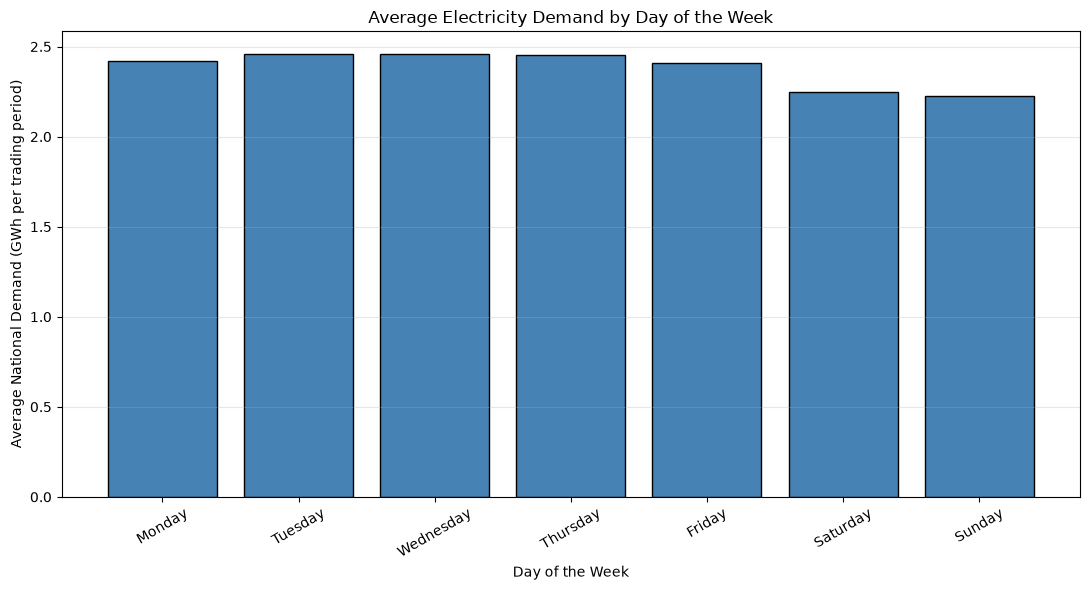

In [40]:
# Extract day of the week from complete trading periods
hourly_demand["Day"] = hourly_demand["Period start"].dt.day_name()

# Define chronological weekday order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate average electricity demand by weekday
weekly_demand = (
    hourly_demand.groupby("Day")["Demand (GWh)"]
    .mean()
    .reindex(day_order)
)

# Visualise weekly demand
plt.figure(figsize=(11, 6))

bars = plt.bar(
    weekly_demand.index,
    weekly_demand.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("Average Electricity Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average National Demand (GWh per trading period)")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 3.7.1 Interpretation of Weekly Electricity Demand

The analysis reveals a consistent difference between weekday and weekend electricity demand across New Zealand.

**Key Findings**

- **Weekday demand:** Average electricity demand is highest between Tuesday and Thursday, reaching approximately 2.46 GWh per trading period.
- **Friday:** Demand decreases slightly to approximately 2.41 GWh.
- **Saturday:** Average demand falls to approximately 2.24 GWh.
- **Sunday:** Records the lowest average demand at approximately 2.22 GWh.

**Possible Explanations**

Higher weekday demand may be associated with commercial operations, industrial production, and business activity.

Lower weekend demand may reflect reduced commercial and industrial electricity consumption.

These explanations are consistent with the observed patterns but have not been independently verified.

**Implications for Predictive Modelling**

The results suggest that day of the week is a potentially useful predictor of electricity demand.

We should consider including:

- Day of the week (Monday–Sunday).
- Weekend indicator (0 = weekday, 1 = weekend).
- Interactions between hour of the day and day of the week.

**Conclusion**

New Zealand's electricity demand exhibits a clear weekly cycle, with higher consumption during weekdays and lower consumption on weekends.

This finding supports incorporating weekly seasonality into future forecasting models.

4. Conclusion and Implications for Forecasting

The exploratory data analysis identified several important patterns in New Zealand’s electricity demand between November 2024 and October 2026.

4.1 Key Findings

1. Annual seasonality: Electricity demand increases during winter and decreases during summer.
2. Daily patterns: Electricity consumption exhibits morning and evening peaks.
3. Weekly patterns: Demand is generally higher on weekdays than weekends.
4. Regional differences: The Upper North Island records the highest average electricity demand.
5. Temporal variation: Daily electricity consumption exhibits recurring seasonal cycles and short-term fluctuations.

4.2 Implications for Machine Learning

These findings suggest that electricity demand can potentially be forecast using historical consumption and calendar-based features.

The next stage will investigate the following predictors:

* Hour of the day: Capture daily consumption patterns.
* Day of the week: Identify differences between weekdays and weekends.
* Month and season: Account for annual seasonality.
* Electricity region: Capture geographical differences in consumption.
* Historical demand (lag features): Use previous observations to predict future demand.
* Rolling averages: Capture recent demand trends and fluctuations.

4.3 Next Steps

The next stage of the project will focus on feature engineering, preparing chronological training and testing datasets, and developing machine learning models.

The following forecasting approaches will be evaluated:

1. Seasonal naive forecasting (baseline).
2. Linear regression.
3. Random forest regression.
4. XGBoost regression.

Model performance will be compared using:

* Mean Absolute Error (MAE)
* Root Mean Squared Error (RMSE)

The objective is to identify which forecasting approach produces the most accurate predictions of regional electricity demand while avoiding data leakage and ensuring that models are evaluated on unseen future observations.

## 5. Exporting the Cleaned Dataset

The cleaned electricity demand dataset is exported for use in subsequent notebooks.

This ensures that data cleaning is performed once and that feature engineering and machine learning use a consistent dataset.

In [41]:
from pathlib import Path

# Keep only the columns needed for demand forecasting
clean_df = df[
    ["Period start", "Period end", "Region ID", "Region", "Demand (GWh)"]
].copy()

# Remove observations with missing demand
clean_df = clean_df.dropna(subset=["Demand (GWh)"])

# Save the cleaned dataset
output_path = Path.cwd().parent / "data" / "electricity_demand_clean.csv"

clean_df.to_csv(output_path, index=False)

print(f"Saved {len(clean_df):,} observations")
print(f"File: {output_path}")

Saved 174,936 observations
File: /Users/javiermorande/Desktop/nz-electricity-forecasting/data/electricity_demand_clean.csv
